In [286]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [287]:
data=pd.read_csv("Position_Salaries.csv")

In [288]:
data.head()

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000


In [289]:
data.dtypes

Position    object
Level        int64
Salary       int64
dtype: object

In [290]:
data.shape

(10, 3)

In [291]:
data.size

30

In [292]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Position  10 non-null     object
 1   Level     10 non-null     int64 
 2   Salary    10 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 372.0+ bytes


In [293]:
data.isna().sum()

Position    0
Level       0
Salary      0
dtype: int64

In [294]:
data.duplicated().sum()

0

In [295]:
core=data[['Level','Salary']].corr()

In [296]:
core

,Level,Salary
Level,1.000000,0.817949
Salary,0.817949,1.000000


<Axes: >

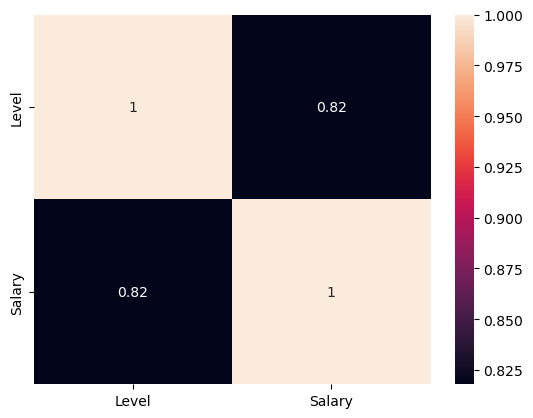

In [297]:
sns.heatmap(core,annot=True)

<BarContainer object of 10 artists>

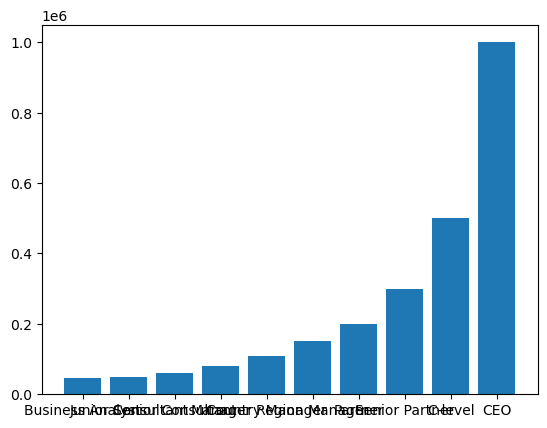

In [298]:
plt.bar(data['Position'],data['Salary'])

<Axes: >

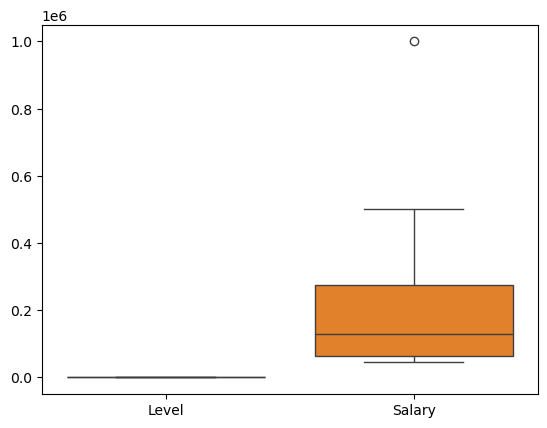

In [299]:
sns.boxplot(data=data)

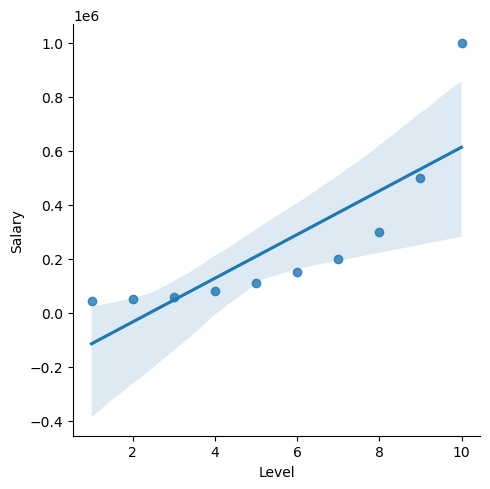

In [300]:
sns.lmplot(x='Level',y='Salary',data=data)

In [301]:
x=data["Level"]

In [302]:
x=x.values.reshape(-1,1)

In [303]:
y=data['Salary']

In [304]:
#y=y.values.reshape(-1,1)

In [305]:
y

0      45000
1      50000
2      60000
3      80000
4     110000
5     150000
6     200000
7     300000
8     500000
9    1000000
Name: Salary, dtype: int64

In [306]:
#polinomial featuring

In [307]:
   from sklearn.preprocessing import PolynomialFeatures

In [308]:
from sklearn.linear_model import LinearRegression

In [309]:
pr=PolynomialFeatures(degree=5)


In [310]:
x_poly=pr.fit_transform(x)

In [311]:
x_poly

array([[1.0000e+00, 1.0000e+00, 1.0000e+00, 1.0000e+00, 1.0000e+00,
        1.0000e+00],
       [1.0000e+00, 2.0000e+00, 4.0000e+00, 8.0000e+00, 1.6000e+01,
        3.2000e+01],
       [1.0000e+00, 3.0000e+00, 9.0000e+00, 2.7000e+01, 8.1000e+01,
        2.4300e+02],
       [1.0000e+00, 4.0000e+00, 1.6000e+01, 6.4000e+01, 2.5600e+02,
        1.0240e+03],
       [1.0000e+00, 5.0000e+00, 2.5000e+01, 1.2500e+02, 6.2500e+02,
        3.1250e+03],
       [1.0000e+00, 6.0000e+00, 3.6000e+01, 2.1600e+02, 1.2960e+03,
        7.7760e+03],
       [1.0000e+00, 7.0000e+00, 4.9000e+01, 3.4300e+02, 2.4010e+03,
        1.6807e+04],
       [1.0000e+00, 8.0000e+00, 6.4000e+01, 5.1200e+02, 4.0960e+03,
        3.2768e+04],
       [1.0000e+00, 9.0000e+00, 8.1000e+01, 7.2900e+02, 6.5610e+03,
        5.9049e+04],
       [1.0000e+00, 1.0000e+01, 1.0000e+02, 1.0000e+03, 1.0000e+04,
        1.0000e+05]])

In [312]:
#linear regression
reg=LinearRegression()
reg.fit(x_poly,y)   #trining the data 

LinearRegression()

In [313]:
y_pred=reg.predict(x_poly)
y_pred

array([ 43895.1048956 ,  53836.82983705,  57065.26806523,  77286.71328647,
       112263.40326306, 152736.59673623, 201349.65034936, 291571.09557096,
       506617.71561785, 998377.62237821])

In [314]:
reg.coef_

array([ 0.00000000e+00,  1.60731002e+05, -1.00378788e+05,  2.81649184e+04,
       -3.44638695e+03,  1.57692308e+02])

In [315]:
reg.intercept_

-41333.33333268948

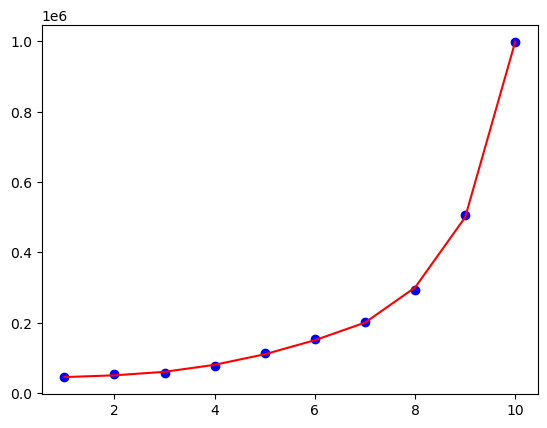

In [316]:
plt.plot(x,y,color='red')
plt.scatter(x,y_pred,color="blue")


In [365]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

In [367]:
mean_absolute_error(y,y_pred)

3360.8391607082463

In [369]:
mean_squared_error(y,y_pred)

16382284.382280022

In [371]:
np.sqrt(mean_squared_error(y,y_pred))

4047.5034752647243

In [373]:
result=pd.DataFrame(columns=['Actual','Predicted'])
result['Actual']=y
result['Predicted']=y_pred

result=result.reset_index()
result.head()

,index,Actual,Predicted
0,0,45000,43895.104896
1,1,50000,53836.829837
2,2,60000,57065.268065
3,3,80000,77286.713286
4,4,110000,112263.403263


In [375]:
r2_score(y,y_pred)

0.9997969027099755